# TLS with a GP baseline: a spotted star with a planet

**Level:** beginner · **Run time:** about a minute on a laptop (the first search also compiles the code) · **Needs:** `batman-package` and `wotan` for this example; a GPU is optional.

Young and active stars vary by percents within a day, while a small planet dims them by a few hundred ppm. The usual approach removes the variability first (detrending, e.g. with a running biweight from [wotan](https://github.com/hippke/wotan)) and then searches the flat light curve with TLS. When the star varies on time scales close to the transit duration, the detrending either leaves residuals or eats part of the transit.

`transitleastsquares.gp` (new in TLS 2.1, experimental) takes another route: it models the star with a Gaussian process (GP) and integrates the GP out *inside* the search, so that every trial transit is fitted jointly with the stellar variability. There is no detrending window to choose.

This notebook simulates a spotted, rotating star with an instrumental trend and a planet, and compares
1. biweight detrending + TLS 2.0 (the classical approach),
2. TLS 2.0 + GP on the CPU,
3. TLS 2.0 + GP on an NVIDIA GPU (skipped if there is none).

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
import batman
from wotan import flatten
from transitleastsquares import transitleastsquares, gp, gpu
from matplotlib import rcParams; rcParams["figure.dpi"] = 120

## A spotted star with a trend and a planet

80 days at 30 min cadence (like Kepler or K2), with a two-day gap. The star rotates in 1.9 days; its spots grow and decay over a few weeks and drift in longitude, so the signal is not strictly periodic. A slow instrumental trend is added. The planet has a period of 6.37 days and a depth of about 750 ppm, and the white noise is 400 ppm per point.

3745 points, transit depth 756 ppm, duration 3.6 h


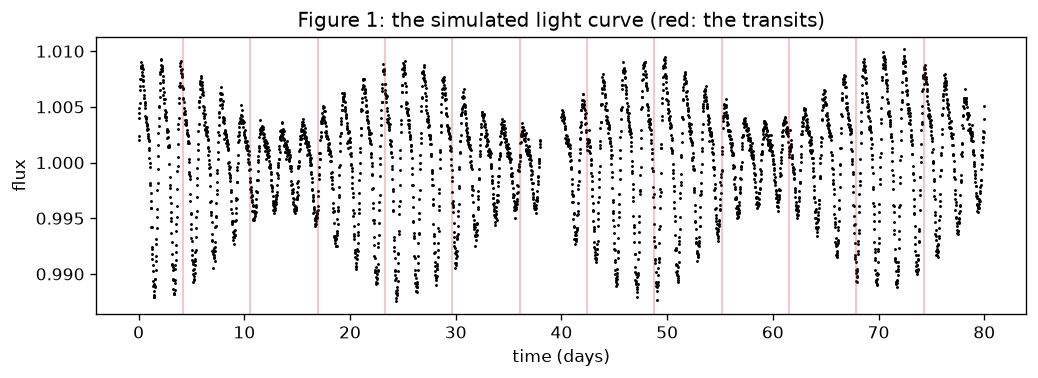

In [2]:
rng = np.random.default_rng(42)
t = np.arange(0, 80, 1 / 48)
t = t[~((t > 38) & (t < 40))]                                   # a gap
prot = 1.9                                                      # rotation period (days)
amp = 6e-3 * (1 + 0.5 * np.sin(2 * np.pi * t / 23 + 1.0))       # spots grow and decay
phase = 0.3 * np.sin(2 * np.pi * t / 31)                        # and drift in longitude
star = 1 + amp * (np.sin(2 * np.pi * t / prot + phase) + 0.35 * np.sin(4 * np.pi * t / prot + 2 * phase + 0.7))
star += 2e-3 * (t / 80) ** 2 - 1e-3 * t / 80                    # slow instrumental trend

p = batman.TransitParams()
p.t0, p.per, p.rp, p.a, p.inc, p.ecc, p.w = 4.2, 6.37, 0.025, 16.0, 90.0, 0.0, 90.0
p.u, p.limb_dark = [0.4, 0.25], "quadratic"
planet = batman.TransitModel(p, t, supersample_factor=7, exp_time=1 / 48).light_curve(p)

dy = np.full(len(t), 4e-4)
y = star * planet + rng.normal(0, 4e-4, len(t))
print(f"{len(t)} points, transit depth {1e6 * (1 - planet.min()):.0f} ppm, duration {24 * (planet < 1).sum() / 48 / 12:.1f} h")

fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(t, y, "k.", ms=1.5)
for tc in np.arange(p.t0, t.max(), p.per):
    ax.axvline(tc, color="tab:red", alpha=0.3, lw=1)
ax.set_xlabel("time (days)"); ax.set_ylabel("flux")
ax.set_title("Figure 1: the simulated light curve (red: the transits)");

## 1. Biweight detrending + TLS 2.0

A biweight window of 0.5 days, about three times the transit duration, as usually recommended.

In [3]:
flat = flatten(t, y, method="biweight", window_length=0.5)
ok = np.isfinite(flat)
t1 = time.perf_counter()
bw = transitleastsquares(t[ok], flat[ok], dy[ok]).power(show_progress_bar=False, verbose=False)
print(f"biweight + TLS: period {bw.period:.3f} d, SDE {bw.SDE:.1f} ({time.perf_counter() - t1:.1f} s)")

biweight + TLS: period 1.899 d, SDE 15.3 (0.4 s)


The strongest peak is not the planet: at this rotation period, the residuals of the detrending dominate the periodogram.

## 2. TLS 2.0 + GP on the CPU

`gp.search` takes the raw (normalised) flux. It first fits the hyperparameters of the GP (by default a rotation kernel with a slow term and white-noise jitter) by maximum likelihood, with a quasi-Newton optimizer and the exact gradient of the likelihood, then searches with the GP marginalised. The period grid is that of TLS.

In [4]:
t1 = time.perf_counter()
r = gp.search(t, y, dy)
print(f"TLS + GP (CPU): period {r.period:.4f} d, T0 {r.T0:.3f}, duration {24 * r.duration:.1f} h, "
      f"depth {1e6 * r.depth:.0f} +- {1e6 * r.depth_err:.0f} ppm, SDE {r.SDE:.1f} ({time.perf_counter() - t1:.1f} s)")
print("fitted baseline:", r.baseline)

TLS + GP (CPU): period 6.3720 d, T0 4.198, duration 3.5 h, depth 765 +- 68 ppm, SDE 24.0 (0.4 s)
fitted baseline: RotationBaseline(sigma=np.float64(0.0048473269559271654), period=np.float64(1.900484229676493), Q0=np.float64(236.43954511335332), dQ=np.float64(2.3474238967561307), f=np.float64(0.1377530923047874), sigma_slow=np.float64(0.00034453620002175014), rho_slow=np.float64(100.00000000000004), jitter=np.float64(8.635303952311724e-06))


The GP finds the planet, and its depth is close to the injected one. The result is a dict whose items are also attributes, much like the results of TLS (see the [documentation](https://transitleastsquares.readthedocs.io/en/latest/GP%20search.html)). `r.trend` is the posterior mean of the GP, conditioned on the data outside the transits of the best signal.

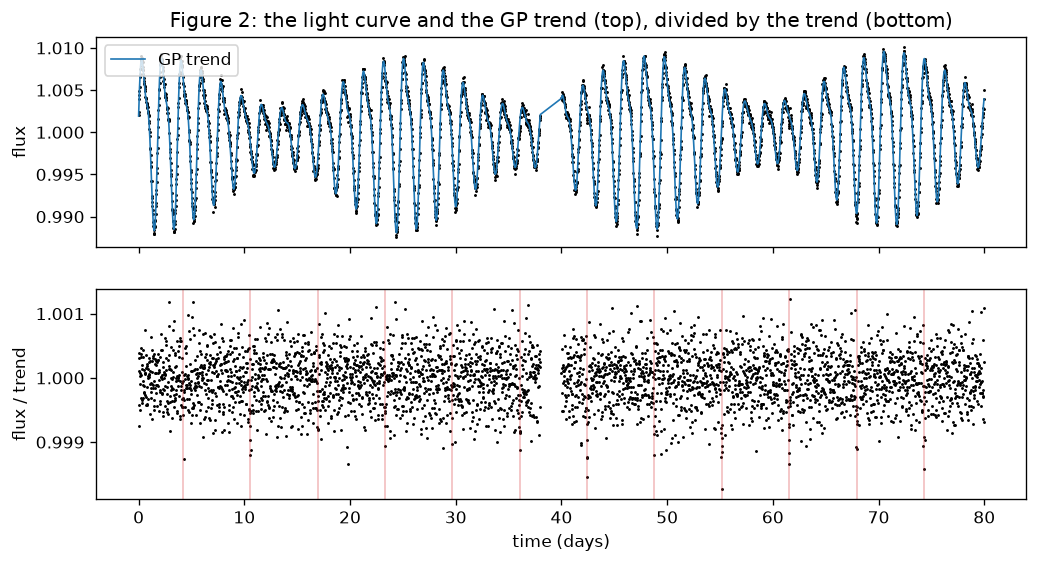

In [5]:
fig, ax = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
ax[0].plot(r.time, r.flux, "k.", ms=1.5)
ax[0].plot(r.time, r.trend, "tab:blue", lw=1, label="GP trend")
ax[0].set_ylabel("flux"); ax[0].legend(loc="upper left")
ax[0].set_title("Figure 2: the light curve and the GP trend (top), divided by the trend (bottom)")
ax[1].plot(r.time, r.flux / r.trend, "k.", ms=1.5)
for tc in r.transit_times:
    ax[1].axvline(tc, color="tab:red", alpha=0.3, lw=1)
ax[1].set_xlabel("time (days)"); ax[1].set_ylabel("flux / trend");

### The decomposition

The search fits the transit depth jointly with the GP for every trial transit. For the best signal, the light curve can be split into its parts: the GP baseline (its posterior mean, conditioned on the data minus the transit), the transit model (the template of the search, at the depth found), and the residuals. The search itself never subtracts the baseline; this is for illustration.

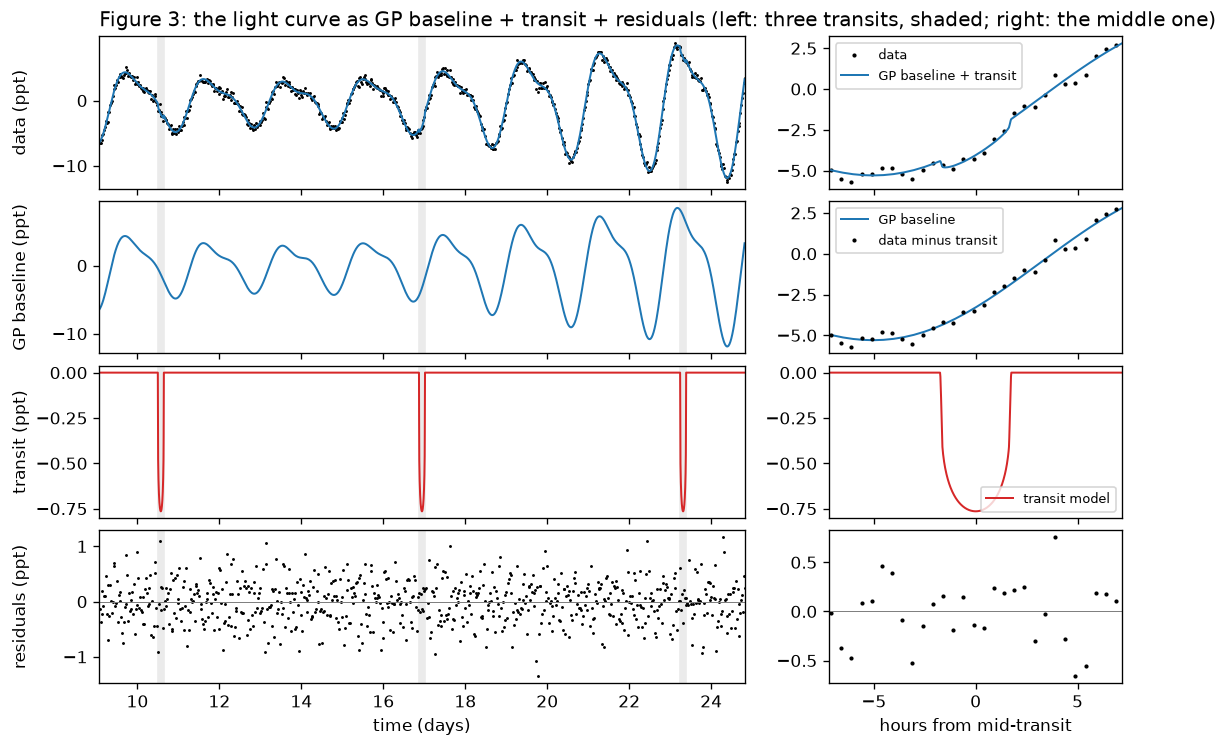

In [6]:
from transitleastsquares.gp.events import template_table   # the transit template of the search

table = template_table()                                    # depth 1 at the bottom, over one duration
def transit(x):
    """The transit model (flux - 1) of the best signal at times x."""
    out = np.zeros(len(x))
    for tc in r.transit_times:
        u = (x - tc) / r.duration + 0.5
        inside = (u > 0) & (u < 1)
        out[inside] -= r.depth * np.interp(u[inside], np.linspace(0, 1, len(table)), table)
    return out

tr = transit(r.time)
base = r.baseline.trend(r.time, r.flux - tr, r.flux_err)    # GP mean, conditioned on the data minus the transit
resid = r.flux - base - tr

k = 2                                                       # transits k-1, k, k+1
tt = r.transit_times
lo, hi = tt[k - 1] - 1.5, tt[k + 1] + 1.5
tc = tt[k]
fig, axs = plt.subplots(4, 2, figsize=(11, 7), sharex="col", gridspec_kw=dict(width_ratios=(2.2, 1), hspace=0.08, wspace=0.18))
for j, (a, b) in enumerate(((lo, hi), (tc - 0.3, tc + 0.3))):
    sel = (r.time >= a) & (r.time <= b)
    xf = np.arange(a, b, 1 / 1440)                          # the model on a 1-min grid
    bf, trf = np.interp(xf, r.time, base), transit(xf)
    x = (lambda v: v) if j == 0 else (lambda v: 24 * (v - tc))
    ms = 1.5 if j == 0 else 3
    axs[0, j].plot(x(r.time[sel]), 1e3 * (r.flux[sel] - 1), "k.", ms=ms, label="data")
    axs[0, j].plot(x(xf), 1e3 * (bf + trf - 1), color="tab:blue", lw=1.2, label="GP baseline + transit")
    axs[1, j].plot(x(xf), 1e3 * (bf - 1), color="tab:blue", lw=1.2, label="GP baseline")
    if j == 1:
        axs[1, j].plot(x(r.time[sel]), 1e3 * (r.flux - tr - 1)[sel], "k.", ms=ms, label="data minus transit")
    axs[2, j].plot(x(xf), 1e3 * trf, color="tab:red", lw=1.2, label="transit model")
    axs[3, j].plot(x(r.time[sel]), 1e3 * resid[sel], "k.", ms=ms)
    axs[3, j].axhline(0, color="0.5", lw=0.6)
    axs[3, j].set_xlim(x(a), x(b))
for i, lab in enumerate(("data (ppt)", "GP baseline (ppt)", "transit (ppt)", "residuals (ppt)")):
    axs[i, 0].set_ylabel(lab)
    for c in tt[k - 1:k + 2]:
        axs[i, 0].axvspan(c - r.duration / 2, c + r.duration / 2, color="0.92", zorder=0)
for i in range(3):
    axs[i, 1].legend(loc="lower right" if i == 2 else "upper left", fontsize=8)
axs[3, 0].set_xlabel("time (days)"); axs[3, 1].set_xlabel("hours from mid-transit")
axs[0, 0].set_title("Figure 3: the light curve as GP baseline + transit + residuals (left: three transits, shaded; right: the middle one)", loc="left")
fig.align_ylabels(axs[:, 0]);

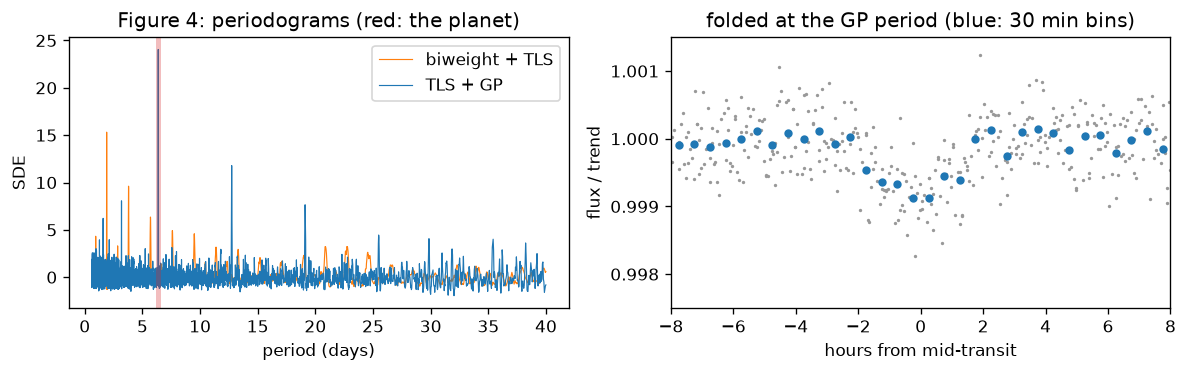

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].plot(bw.periods, bw.power, color="tab:orange", lw=0.7, label="biweight + TLS")
ax[0].plot(r.periods, r.power, color="tab:blue", lw=0.7, label="TLS + GP")
ax[0].axvline(p.per, color="tab:red", alpha=0.3, lw=3)
ax[0].set_xlabel("period (days)"); ax[0].set_ylabel("SDE"); ax[0].legend()
ax[0].set_title("Figure 4: periodograms (red: the planet)")

P = r.period
ph = ((r.time - r.T0 + 0.5 * P) % P - 0.5 * P) * 24
d = r.flux / r.trend
ax[1].plot(ph, d, ".", color="0.6", ms=2)
edges = np.arange(-8, 8.01, 0.5)
mid = 0.5 * (edges[1:] + edges[:-1])
binned = [np.mean(d[(ph >= a) & (ph < b)]) for a, b in zip(edges[:-1], edges[1:])]
ax[1].plot(mid, binned, "o", color="tab:blue", ms=4)
ax[1].set_xlim(-8, 8); ax[1].set_ylim(0.9975, 1.0015)
ax[1].set_xlabel("hours from mid-transit"); ax[1].set_ylabel("flux / trend")
ax[1].set_title("folded at the GP period (blue: 30 min bins)")
plt.tight_layout()

## 3. TLS 2.0 + GP on the GPU

With an NVIDIA GPU, `device="gpu"` runs the fit, the Kalman passes, the single transit events and the period fold on the GPU (install with `pip install "transitleastsquares[gpu]"`). The results equal those of the CPU up to rounding. For short light curves like this one, the CPU is about as fast; the GPU pays for long light curves, e.g. two years of PLATO data with millions of points (see tutorial 14).

In [8]:
import warnings
warnings.filterwarnings("ignore", message="Grid size")   # numba-cuda: low occupancy on short light curves
if gpu.available():
    gp.search(t, y, dy, device="gpu")   # the first call compiles the GPU kernels
    t1 = time.perf_counter()
    rg = gp.search(t, y, dy, device="gpu")
    print(f"TLS + GP (GPU): period {rg.period:.4f} d, SDE {rg.SDE:.1f} ({time.perf_counter() - t1:.1f} s)")
    print(f"difference to the CPU: period {rg.period - r.period:.1e} d, SDE {rg.SDE - r.SDE:+.3f}")
else:
    print("No CUDA GPU found: skipped.")

TLS + GP (GPU): period 6.3720 d, SDE 24.0 (0.2 s)
difference to the CPU: period 0.0e+00 d, SDE +0.000


## Options

* `period_min`, `period_max`, `oversampling_factor`, `n_transits_min`, `R_star_min` ... `M_star_max`: the search grid, as in TLS.
* `baseline="spline"`: a smoothing spline instead of the rotation kernel, or a fixed `gp.RotationBaseline(...)` (no fit).
* `segment_gap=0.5`: light curves made of segments with offsets between them (e.g. quarters, sectors): each segment gets its own filter and free mean, and a polynomial (`segment_degree`, default 4).
* `fit_method="nelder-mead"`: the derivative-free fit, the default of TLS 2.1 (about 30 times more likelihood evaluations); `fit_device="cpu"`: fit on the CPU and search on the GPU (several processes sharing one GPU).
* `use_threads`: CPU threads; `trend=False` skips the trend (faster).

For detrended light curves, TLS also has new backends for long light curves: `power(backend="events")`, `"events-ffa"` and `"events-gpu"`. See the [documentation](https://transitleastsquares.readthedocs.io/en/latest/index.html).